In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models

In [3]:
df = pd.read_csv("data/train.csv")

In [4]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df.shape

(42000, 785)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [9]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='str', length=785)

In [13]:
df.isnull().sum()

label       0
pixel0      0
pixel1      0
pixel2      0
pixel3      0
           ..
pixel779    0
pixel780    0
pixel781    0
pixel782    0
pixel783    0
Length: 785, dtype: int64

In [29]:
X = df.drop(columns=["label"]).values
y = df["label"].values

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [31]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [32]:
X_train_img = X_train.reshape(-1,28,28)
X_test_img = X_test.reshape(-1,28,28)

In [35]:
y_train_cat = to_categorical(y_train,10)
y_test_cat = to_categorical(y_test,10)

In [36]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [37]:
perceptron.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

In [39]:
history_perceptron = perceptron.fit(
    X_train_img, y_train_cat,
    epochs=10,
    batch_size=16,
    validation_data=(X_test_img, y_test_cat),
    verbose=1
)

Epoch 1/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8122 - loss: 0.7849 - val_accuracy: 0.8699 - val_loss: 0.5043
Epoch 2/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8828 - loss: 0.4532 - val_accuracy: 0.8840 - val_loss: 0.4235
Epoch 3/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8938 - loss: 0.3986 - val_accuracy: 0.8913 - val_loss: 0.3901
Epoch 4/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8995 - loss: 0.3711 - val_accuracy: 0.8961 - val_loss: 0.3707
Epoch 5/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9038 - loss: 0.3537 - val_accuracy: 0.8989 - val_loss: 0.3578
Epoch 6/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9067 - loss: 0.3413 - val_accuracy: 0.9021 - val_loss: 0.3483
Epoch 7/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9094 - loss: 0.3318 - val_accuracy: 0.9042 - val_loss: 0.3410
Epoch 8/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9107 - loss: 0.3243 - 

In [42]:
acc_perceptron = perceptron.evaluate(X_test_img, y_test_cat, verbose=1)[1]
acc_perceptron

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9081 - loss: 0.3263


0.9080952405929565

In [43]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [48]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [53]:
history_ann = ann.fit(
    X_train_img, y_train_cat,
    epochs=10,
    batch_size=16,
    validation_data=(X_test_img, y_test_cat),
    verbose=1
)

Epoch 1/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9133 - loss: 0.2930 - val_accuracy: 0.9533 - val_loss: 0.1609
Epoch 2/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9617 - loss: 0.1251 - val_accuracy: 0.9642 - val_loss: 0.1197
Epoch 3/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9752 - loss: 0.0815 - val_accuracy: 0.9648 - val_loss: 0.1178
Epoch 4/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9828 - loss: 0.0562 - val_accuracy: 0.9670 - val_loss: 0.1144
Epoch 5/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9871 - loss: 0.0408 - val_accuracy: 0.9663 - val_loss: 0.1297
Epoch 6/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9874 - loss: 0.0390 - val_accuracy: 0.9656 - val_loss: 0.1334
Epoch 7/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9898 - loss: 0.0290 - val_accuracy: 0.9683 - val_loss: 0.1337
Epoch 8/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9920 - loss: 0.0233 - 

In [54]:
acc_ann = ann.evaluate(X_test_img, y_test_cat, verbose=1)[1]
acc_ann

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9663 - loss: 0.1670


0.966269850730896

In [66]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

In [67]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(128, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax"),
])

In [68]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [69]:
history_cnn = cnn.fit(X_train_cnn, y_train_cat, epochs=10, batch_size=16, validation_data=(X_test_cnn, y_test_cat), verbose=1)

Epoch 1/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8877 - loss: 0.3722 - val_accuracy: 0.9596 - val_loss: 0.1320
Epoch 2/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9648 - loss: 0.1288 - val_accuracy: 0.9737 - val_loss: 0.0875
Epoch 3/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9752 - loss: 0.0910 - val_accuracy: 0.9777 - val_loss: 0.0795
Epoch 4/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9799 - loss: 0.0783 - val_accuracy: 0.9824 - val_loss: 0.0634
Epoch 5/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9853 - loss: 0.0538 - val_accuracy: 0.9822 - val_loss: 0.0717
Epoch 6/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9867 - loss: 0.0504 - val_accuracy: 0.9834 - val_loss: 0.0671
Epoch 7/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9875 - loss: 0.0437 - val_accuracy: 0.9827 - val_loss: 0.0813
Epoch 8/10
1838/1838 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9901 - loss: 0

In [72]:
acc_cnn = cnn.evaluate(X_test_cnn, y_test_cat, verbose=1)[1]
acc_cnn

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9844 - loss: 0.0736


0.9843651056289673

In [73]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

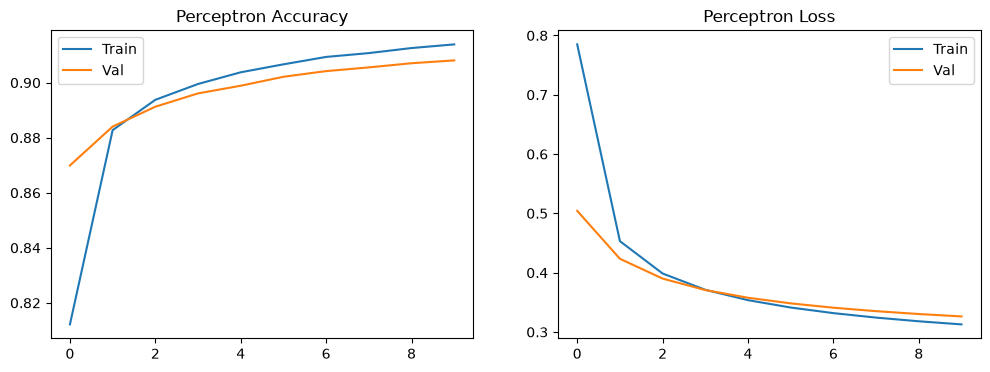

In [77]:
plot_training(history_perceptron, "Perceptron")

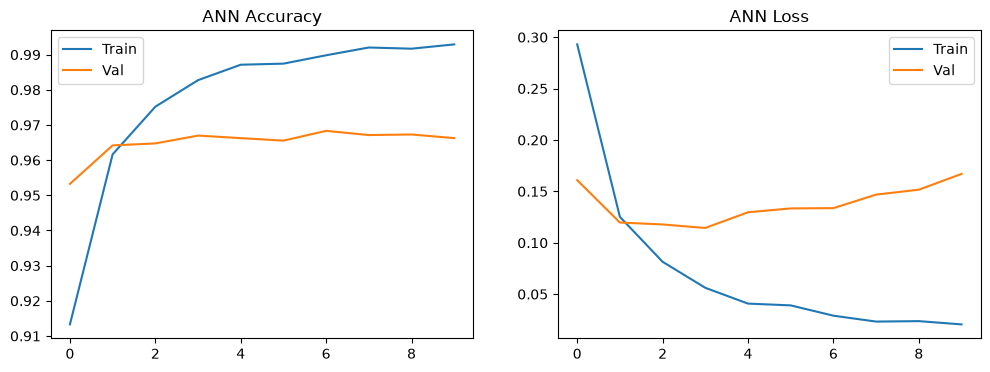

In [78]:
plot_training(history_ann, "ANN")

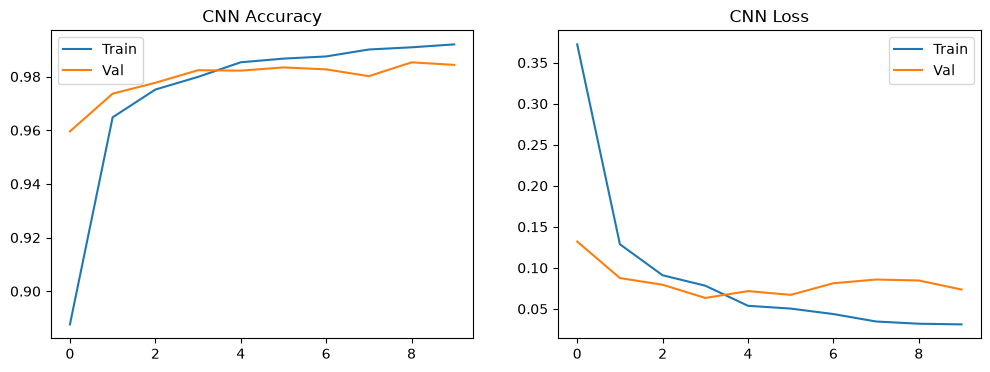

In [79]:
plot_training(history_cnn, "CNN")

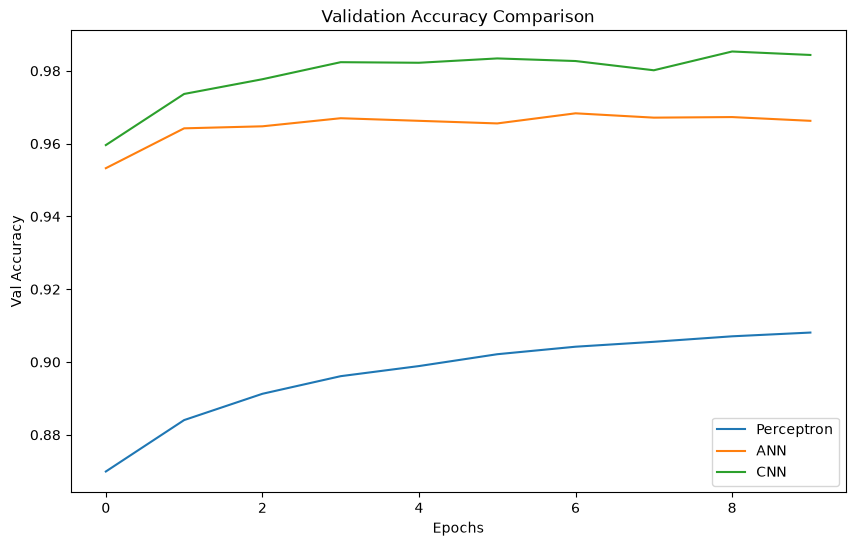

In [81]:
plt.figure(figsize=(10,6))
plt.plot(history_perceptron.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [82]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


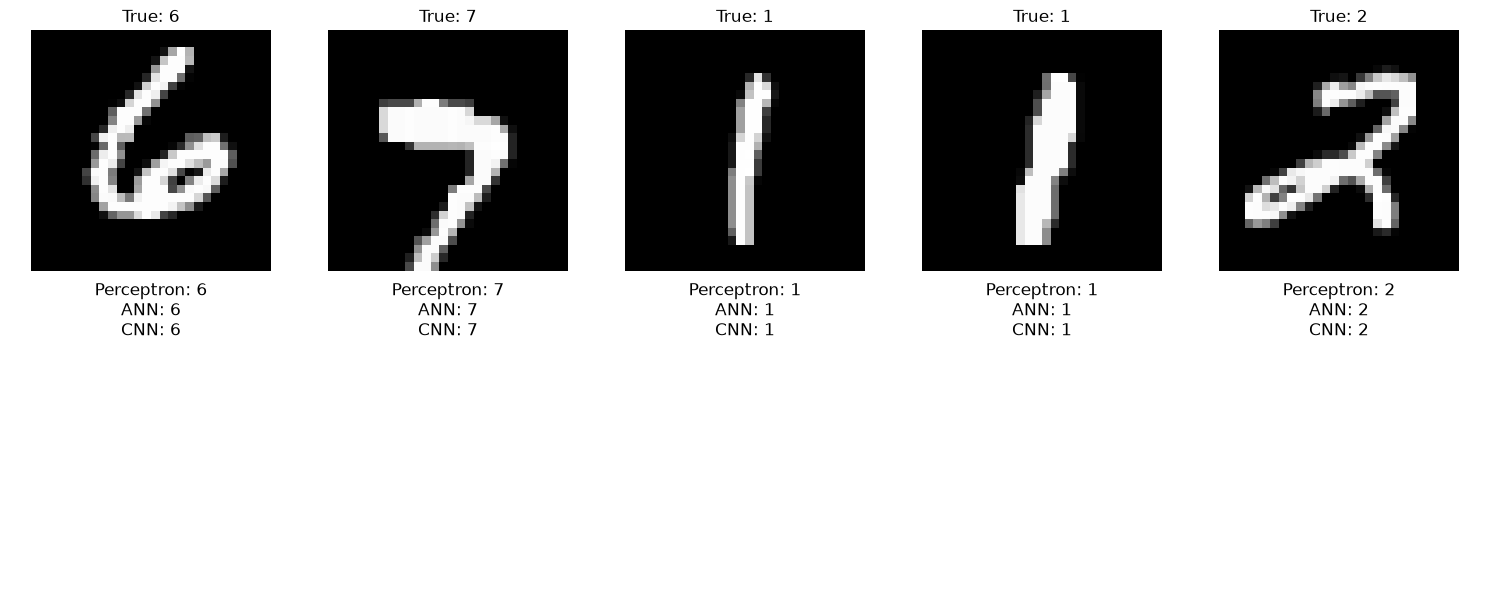

In [85]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)